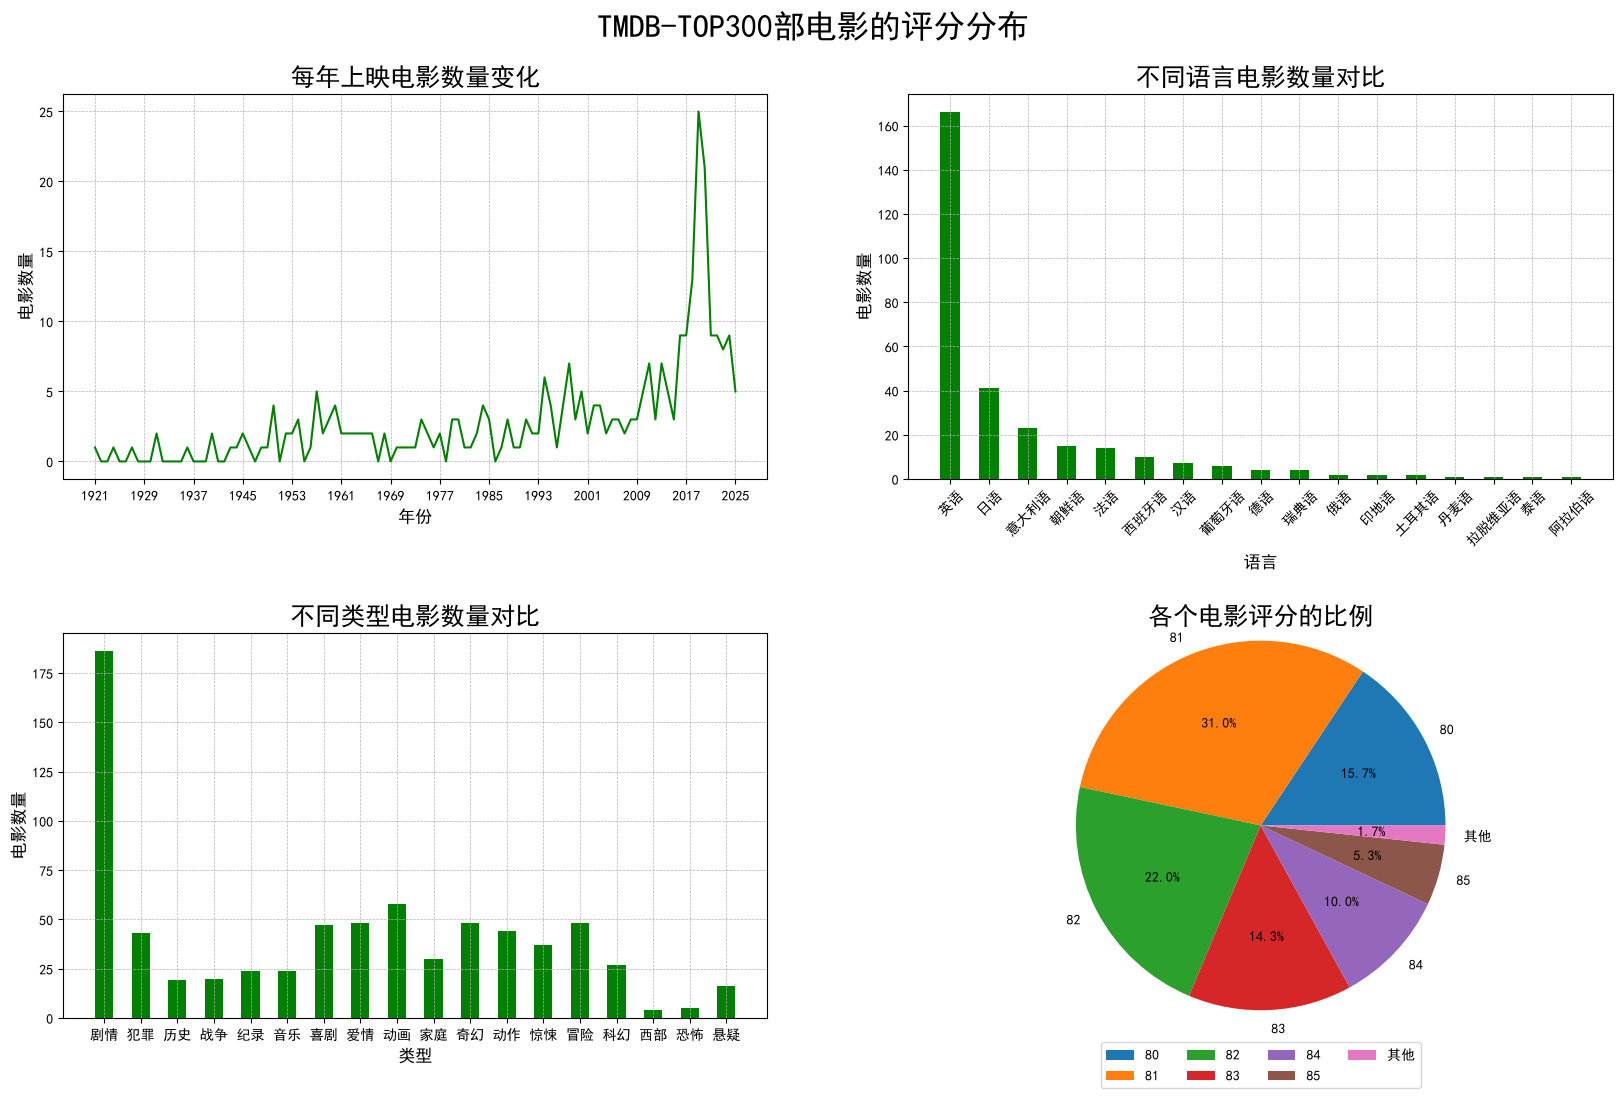

In [31]:
from matplotlib.axes import Axes
import matplotlib.pyplot as plt
import pandas as pd
from pandas import Series

# 展示中文
plt.rcParams['font.sans-serif'] = ['SimHei'] # 设置中文字体为黑体

# 创建子图
figure, axes = plt.subplots(nrows=2, ncols=2, figsize=(20,12), dpi=100) # nrows表示行数，ncols表示列数，figsize表示图形大小，dpi表示分辨率
figure.suptitle('TMDB-TOP300部电影的评分分布', fontsize=23, x=0.5, y=0.95) # 设置总标题
figure.subplots_adjust(hspace=0.4, wspace=0.2) # 设置子图间距，hspace表示高度间距，wspace表示宽度间距

# 获取子图
axes1: Axes = axes[0][0] # 获取第一个子图
axes2: Axes = axes[0][1] # 获取第二个子图
axes3: Axes = axes[1][0] # 获取第三个子图
axes4: Axes = axes[1][1] # 获取第四个子图

# 加载数据
# int64: 整型数字（不支持空值）
# float64: 浮点型数字（支持空值）
# Int64: 整型数字（支持空值）
data = pd.read_csv('../data/movies.csv', usecols=['电影名', '年份', '上映时间', '类型', '时长', '评分', '语言'], dtype={'年份': 'Int64'}) # 读取前30行数据，并指定列的数据类型

# 1. 统计TOP300的电影中，每一年上映的电影数量的变化。（折线图）
# 1.1 缺省值、异常值处理
data['年份'] = data['年份'].fillna(data['上映时间'].str[:4]) # 用上映时间的前四位填充年份的缺省值

# 1.2 数据分组
year_counts = data.groupby('年份')['年份'].count() # 统计每一年上映的电影数量

# 1.3 组装数据
# x轴数据
min_year = year_counts.index.min() # 获取最小年份
max_year = year_counts.index.max() # 获取最大年份
x = [i for i in range(min_year, max_year + 1)]

# y轴数据
y = [int(year_counts.get(i, 0)) for i in x] # 获取每一年上映的电影数量，如果没有上映的电影，则为0

# 1.4 绘制折线图
axes1.plot(x, y, color='green')
axes1.set_xlabel('年份', fontsize=12)
axes1.set_ylabel('电影数量', fontsize=12)
axes1.set_title('每年上映电影数量变化', fontsize=18)

axes1.set_xticks(x[::8]) # 设置x轴刻度，每隔8年显示一个刻度
y_ticks = [i for i in range(0, max(y) + 1, 5)] # 设置y轴刻度，每隔5个电影数量显示一个刻度
axes1.set_yticks(y_ticks) # 设置y轴刻度
axes1.grid(linestyle='--', linewidth=0.5)

# 2. 统计对比不同语言电影数量。（柱状图）
# 2.1 获取不同语言对应的电影数量
language_counts = data.groupby('语言')['语言'].count().sort_values(ascending=False) # 统计不同语言的电影数量
x_language = language_counts.index.tolist() # 获取语言列表
y_language = language_counts.values.tolist() # 获取对应的电影数量列表

# 2.2 绘制柱状图
axes2.bar(x_language, y_language, color='green', width=0.5)
axes2.set_xlabel('语言', fontsize=12)
axes2.set_ylabel('电影数量', fontsize=12)
axes2.set_title('不同语言电影数量对比', fontsize=18)
axes2.grid(linestyle='--', linewidth=0.5) # 设置x轴刻度
axes2.tick_params(axis='x', rotation=45)

# 3. 统计对比不同类型电影数量。（柱状图）
# 3.1 获取不同类型对应的电影数量
type_count = {}
for types in data['类型'].str.split(','): # 遍历每一行的类型
    for t in types:
        if t in type_count:
            type_count[t] += 1
        else:
            type_count[t] = 1
x_types = list(type_count.keys())
y_types = list(type_count.values())

# 3.2 绘制柱状图
axes3.bar(x_types, y_types, color='green', width=0.5)
axes3.set_xlabel('类型', fontsize=12)
axes3.set_ylabel('电影数量', fontsize=12)
axes3.set_title('不同类型电影数量对比', fontsize=18)
axes3.grid(linestyle='--', linewidth=0.5) # 设置x轴刻度

# 4.统计对比各个电影评分的比例。（饼状图）
# 4.1 获取评分对应的电影数量
rating_counts = data.groupby('评分')['评分'].count() # 统计不同评分的电影数量

# 合并小数据（比例 < 2%） -> 其他评分
total = rating_counts.sum() # 计算总数
large_rating: Series = rating_counts.loc[rating_counts / total >= 0.02] # 获取比例大于等于2%的评分
small_rating: Series = rating_counts.loc[rating_counts / total < 0.02] # 获取比例小于2%的评分

if small_rating.shape[0] > 0: # 如果存在小数据
    other_count = small_rating.sum() # 计算小数据的总数
    large_rating['其他'] = other_count # 将小数据合并为其他评分

x_rating = large_rating.index.tolist() # 获取评分列表
y_rating = large_rating.values.tolist() # 获取对应的电影数量列表

# 4.2 绘制饼状图
axes4.pie(y_rating, labels=x_rating, autopct='%1.1f%%', startangle=0, radius=1.2) # 绘制饼状图，使用Paired颜色映射
axes4.set_title('各个电影评分的比例', fontsize=18)
axes4.legend(loc='lower center', ncol=4, bbox_to_anchor=(0.5, -0.2)) # 显示图例, ncol表示图例列数，bbox_to_anchor表示图例位置(0.5: 控制水平位置, -0.2: 控制垂直位置)表示图例在x轴中间，y轴下方

plt.show()
